# Darcy flow with symmetric observations (64-D, bimodal)

The target is the posterior of a Darcy-flow inverse problem from Che, Chen, Huan, Huang & Wang
(GMBBVI), ported to JAX in `gmmvi/targets/darcy_symmetry.py`. The unknown $\theta\in\mathbb R^{64}$
holds the KL coefficients of the log-permeability $\log\kappa$ on $[0,1]^2$. The pressure is read
on a $15\times15$ sensor lattice and averaged with its mirror image in $x$, which leaves 120
observations:

$$y_{ij}(\theta)=\tfrac12\big(h(x_i,y_j;\theta)+h(1-x_i,y_j;\theta)\big)+\sigma_\eta\eta_{ij}.$$

The data cannot tell $\theta$ from its mirror $s\odot\theta$, $s_l=(-1)^{l_1}$, so the posterior
has exactly two modes: one near the truth and one near its mirror. The prior is
$\mathcal N(0,5I)$, the truth is drawn with $\sigma_0=5$, and the data come from a $3\times$ finer
mesh, so the coarse-model error is part of the posterior.

Each method fits a mixture of $K=5$ components for 1000 iterations from a shared
initialisation. The settings are in `configs/darcy_symmetry/base.toml`.

In [19]:
%matplotlib inline
# Figures are embedded in the notebook as PNG (displayed) and vector PDF; none is written to disk.
%config InlineBackend.figure_formats = ["png", "pdf"]
import os
# Pin the kernel to ONE physical GPU BEFORE importing JAX (indices change between sessions --
# re-check `nvidia-smi` and pick an idle card). Post-hoc evaluation below re-evaluates the
# posterior on stored snapshots: every log_prob is a PDE solve, so a GPU matters.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "3")
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import json
import numpy as np
import jax, jax.numpy as jnp
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
jax.config.update("jax_enable_x64", True)

from gmmvi import benchmark, metrics, plotting

GROUP   = "darcy_symmetry"
RUN     = "darcy_symmetry/base"
CFG     = benchmark.load_config(GROUP)

## 1. The saved run

In [20]:
RESULTS = benchmark.require_results(RUN)
SEEDS   = sorted({s for _, s in RESULTS})
METHODS = [m for m in ["ibw", "gmbbvi", "semtrux", "WFR"] if any(k[0] == m for k in RESULTS)]
GROUPED = benchmark.group_seeds(RESULTS, METHODS)

SPREAD       = "std"
SPREAD_LABEL = rf"mean $\pm$ 1 s.d. over {len(SEEDS)} seeds"
SEED    = SEEDS[0]
RES     = {m: GROUPED[m][SEED] for m in METHODS}
K, N_ITER = RES[METHODS[0]].K, RES[METHODS[0]].n_iterations
m0      = RES[METHODS[0]].means_log[0]
TARGET_KWARGS = CFG.get("target_kwargs", {})

## 2. The target

In [21]:
from gmmvi.targets import registry

spec = registry.build(CFG.get("target", GROUP), **TARGET_KWARGS)
prob = spec.meta["problem"]
DIM  = spec.dim

_r0  = RES[METHODS[0]]
_X0  = metrics.sample_gmm(_r0.means_log[0], _r0.covs_log[0], _r0.weights_log[0], 4000, 0)
_kl0 = float(np.mean(metrics.mixture_log_prob(_X0, _r0.means_log[0], _r0.covs_log[0],
                                              _r0.weights_log[0])
                     - np.asarray(spec.log_prob_np(_X0))))
assert abs(_kl0 - float(_r0.kls[0])) / max(1.0, abs(float(_r0.kls[0]))) < 0.10, \
    "the rebuilt target is not the one the run optimised"

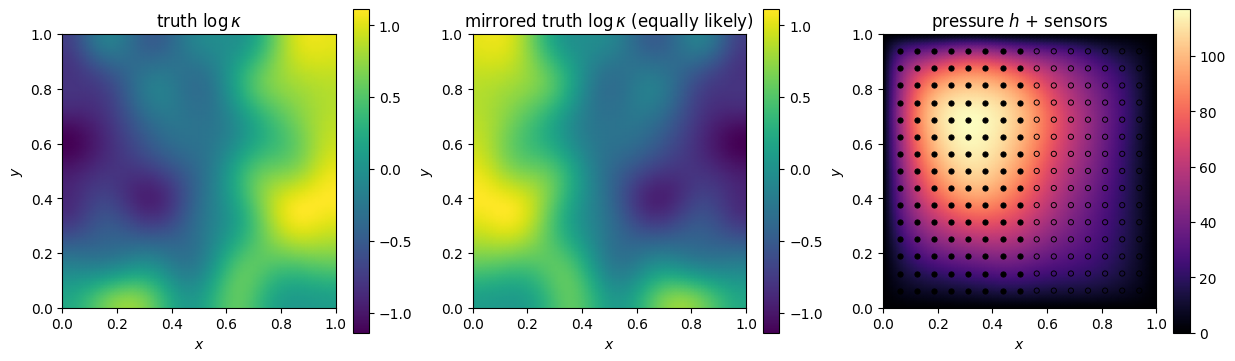

In [22]:
xx = prob.xx
XX, YY = np.meshgrid(xx, xx, indexing="ij")
la_truth  = prob.log_kappa_2d(prob.theta_ref)
la_mirror = la_truth[::-1, :]
h_truth   = prob.pressure_2d(prob.theta_ref)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, Z, ttl, cmap in [(axes[0], la_truth,  r"truth $\log\kappa$", "viridis"),
                         (axes[1], la_mirror, r"mirrored truth $\log\kappa$ (equally likely)", "viridis"),
                         (axes[2], h_truth,   r"pressure $h$ + sensors", "magma")]:
    c = ax.pcolormesh(XX, YY, Z, cmap=cmap, shading="gouraud")
    ax.set(title=ttl, xlabel="$x$", ylabel="$y$"); ax.set_aspect("equal"); fig.colorbar(c, ax=ax)
_xk, _xh = prob.x_locs[:prob._n_keep], prob.x_locs[prob._n_keep:]
for _xsel, _fc in [(_xk, "black"), (_xh, "none")]:
    axes[2].scatter(XX[np.ix_(_xsel, prob.y_locs)], YY[np.ix_(_xsel, prob.y_locs)],
                    s=14, facecolors=_fc, edgecolors="black", linewidths=0.7)
plt.show()

## 3. The shared initialisation

Every method starts from the same mixture. The means are independent draws from
$\mathcal N(0,5I)$ and the covariances are $10^{-4}I$.

In [23]:
_init = benchmark.make_init(CFG, spec, SEED)
assert np.array_equal(_init.means, m0), "the config's init does not reproduce the stored means"
assert np.allclose(_init.covariances, _init.covariances[0, 0, 0] * np.eye(DIM))
for m in METHODS:
    assert np.allclose(RES[m].means_log[0], m0), f"{m} started from a different init?"
    assert np.allclose(RES[m].covs_log[0], _init.covariances, rtol=1e-6, atol=0), m
print("init means:       ||m_k|| in [%.1f, %.1f]"
      % (np.linalg.norm(m0, axis=1).min(), np.linalg.norm(m0, axis=1).max()))
print("init covariances: %.0e * I" % _init.covariances[0, 0, 0])

init means:       ||m_k|| in [16.4, 19.6]
init covariances: 1e-04 * I


## 4. Convergence

The $-$ELBO on the shared evaluator, which scores every stored snapshot with the same random
numbers for all methods. The y-axis is symlog because the curve crosses zero.

IBW     : -ELBO   46331.5 ->     841.3    754.7s   421,000 target evals   
GMBBVI  : -ELBO   46331.5 ->     116.3   1245.8s   2,661,000 target evals   
SEMTRUX : -ELBO   46331.5 ->     116.3   3487.5s   2,661,000 target evals   
WFR     : -ELBO   46331.5 ->     116.2   3275.3s   2,661,000 target evals   


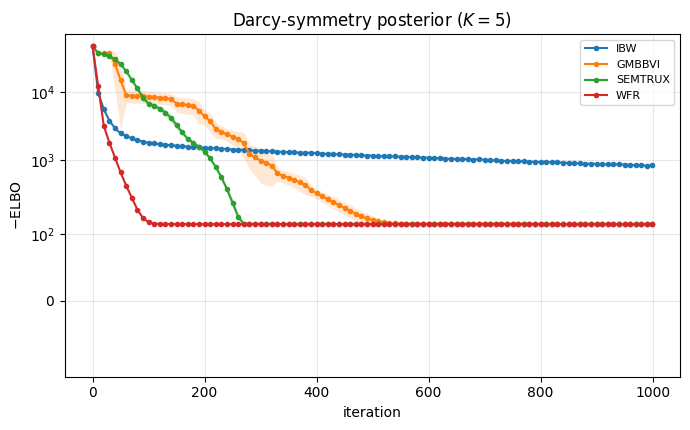

In [ ]:
KL_ITERS, kls = benchmark.kl_traces(GROUPED, spec=spec, config=CFG)

for m in METHODS:
    Y    = kls[m]
    mean = np.nanmean(np.where(np.isfinite(Y), Y, np.nan), axis=0)
    rt   = np.mean([r.runtime_s for r in GROUPED[m].values()])
    print(f"{plotting.LABELS[m]:8s}: -ELBO {mean[0]:9.1f} -> {mean[-1]:9.1f}   "
          )

fig, ax = plt.subplots(figsize=(7, 4.4))
plotting.trace_panel({m: (KL_ITERS, kls[m]) for m in METHODS}, ax=ax,
                     ylabel=r"$-$ELBO",
                     title=f"Darcy-symmetry posterior ($K = {K}$)",
                     logy="symlog", spread=SPREAD)
plt.tight_layout(); plt.show()

## 5. Posterior marginals and recovered fields

The fitted mixture's 1-D marginals at the first 16 coordinates, then the $\log\kappa$ fields of the
truth-side and mirror-side weighted means next to the truth and its mirror.

In [25]:
METHOD_DETAIL = "WFR"
W_EPS = 1e-8
_nrm = np.linalg.norm(la_truth)

def classify(means):
    d1 = np.array([np.linalg.norm(prob.log_kappa_2d(mm) - la_truth) for mm in means])
    d2 = np.array([np.linalg.norm(prob.log_kappa_2d(mm) - la_mirror) for mm in means])
    return d1 < d2, np.minimum(d1, d2) / _nrm

def norm_weights(r):
    w = np.asarray(r.weights, float)
    return w / w.sum()

def side_mean(r, mask):
    w = norm_weights(r)
    if not mask.any() or w[mask].sum() < W_EPS:
        return None
    return (w[mask] @ r.means[mask]) / w[mask].sum()

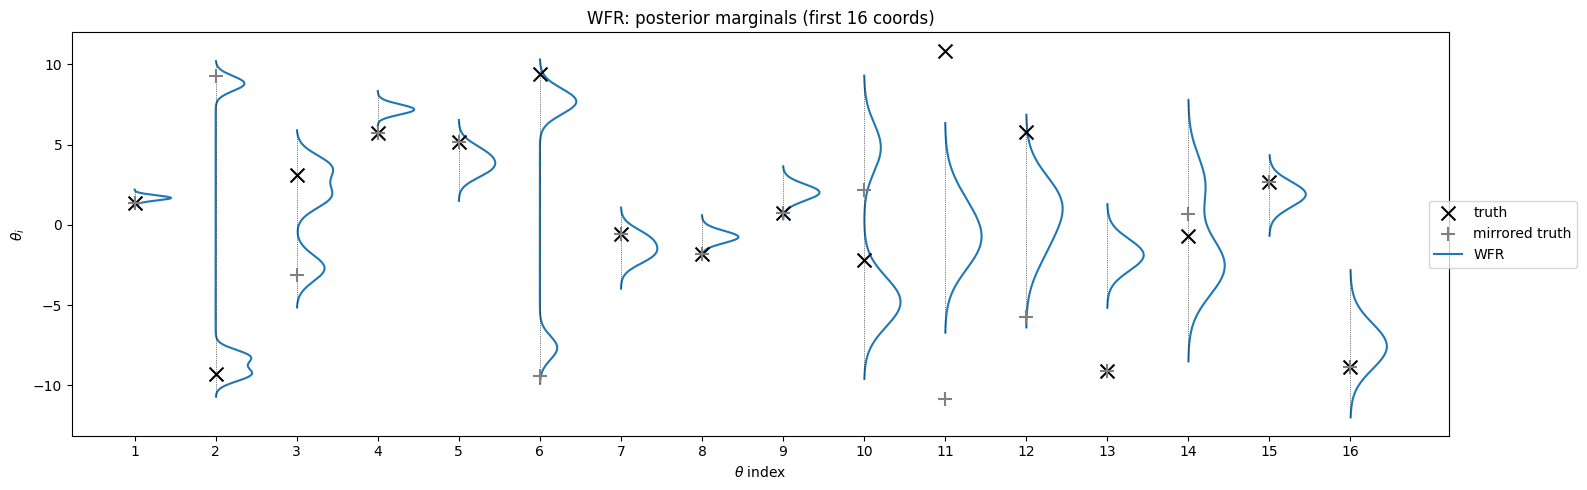

In [26]:
r = RES[METHOD_DETAIL]
side_fin, _ = classify(r.means)
n_ind = 16
fig, ax = plt.subplots(figsize=(16, 5))
ax.scatter(np.arange(1, n_ind + 1), prob.theta_ref[:n_ind], s=100, marker="x",
           color="black", label="truth", zorder=5)
ax.scatter(np.arange(1, n_ind + 1), prob.mirror(prob.theta_ref)[:n_ind], s=100,
           marker="+", color="gray", label="mirrored truth", zorder=5)
_w = norm_weights(r)
for i in range(n_ind):
    mu, sd = r.means[:, i], np.sqrt(r.covariances[:, i, i])
    grid = np.linspace((mu - 3 * sd).min(), (mu + 3 * sd).max(), 400)
    dens = sum(_w[k] * np.exp(-0.5 * ((grid - mu[k]) / sd[k]) ** 2)
               / (sd[k] * np.sqrt(2 * np.pi)) for k in range(K))
    ax.plot(i + 1 + dens / dens.max() * 0.45, grid, "-", color="C0",
            label=plotting.LABELS[METHOD_DETAIL] if i == 0 else None)
    ax.plot(np.full_like(grid, i + 1), grid, ":", color="black", lw=0.5)
ax.set(xticks=np.arange(1, n_ind + 1), xlabel=r"$\theta$ index", ylabel=r"$\theta_i$",
       title=f"{plotting.LABELS[METHOD_DETAIL]}: posterior marginals (first {n_ind} coords)")
ax.legend(loc="center left", bbox_to_anchor=(0.98, 0.5))
plt.tight_layout(); plt.show()

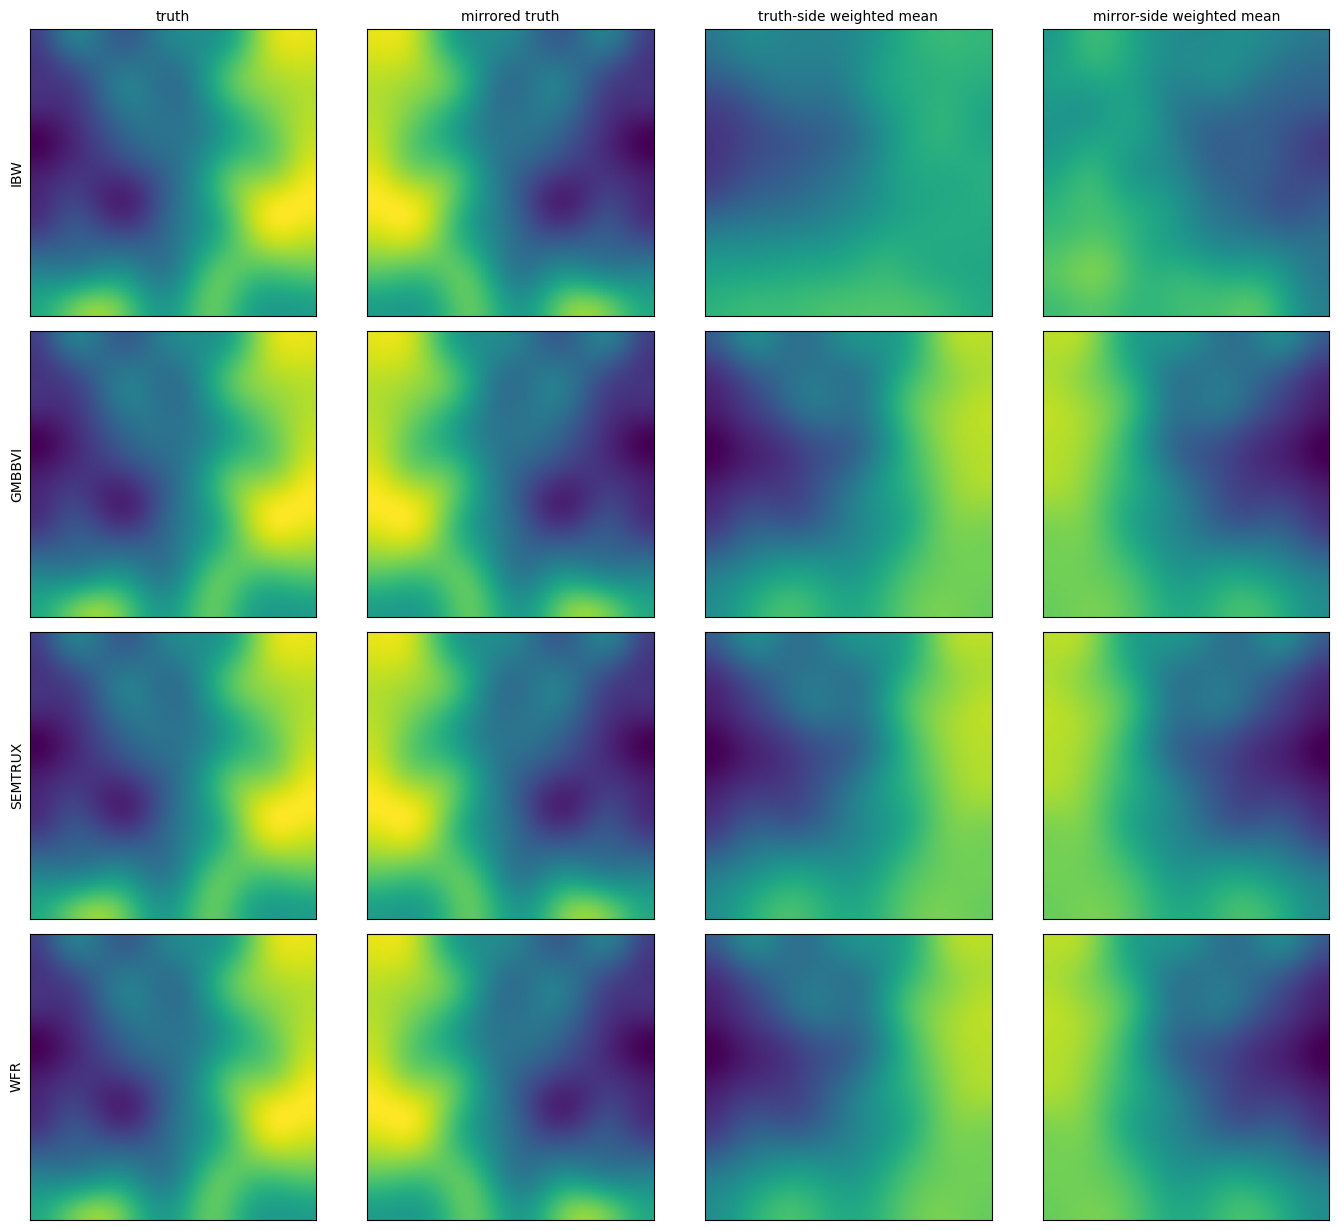

In [27]:
fig, axes = plt.subplots(len(METHODS), 4, figsize=(14, 3.1 * len(METHODS)), squeeze=False)
vmin, vmax = la_truth.min(), la_truth.max()
for row, m in enumerate(METHODS):
    r = RES[m]; side, _ = classify(r.means)
    panels = [("truth", la_truth), ("mirrored truth", la_mirror)]
    for name, msk in [("truth-side weighted mean", side), ("mirror-side weighted mean", ~side)]:
        th = side_mean(r, msk)
        if th is not None:
            panels.append((name, prob.log_kappa_2d(th)))
        else:
            panels.append((name + " (NO MASS)", np.full_like(la_truth, np.nan)))
    for col, (name, Z) in enumerate(panels):
        ax = axes[row, col]
        ax.pcolormesh(XX, YY, Z, cmap="viridis", vmin=vmin, vmax=vmax, shading="gouraud")
        ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
        if row == 0: ax.set_title(name, fontsize=10)
    axes[row, 0].set_ylabel(plotting.LABELS[m])
plt.tight_layout(); plt.show()